Auto-assigning NUTS sampler...
Initializing NUTS using jitter+adapt_diag...
Multiprocess sampling (4 chains in 4 jobs)
NUTS: [l2_effectiveness]


Sampling 4 chains for 500 tune and 1_000 draw iterations (2_000 + 4_000 draws total) took 1 seconds.


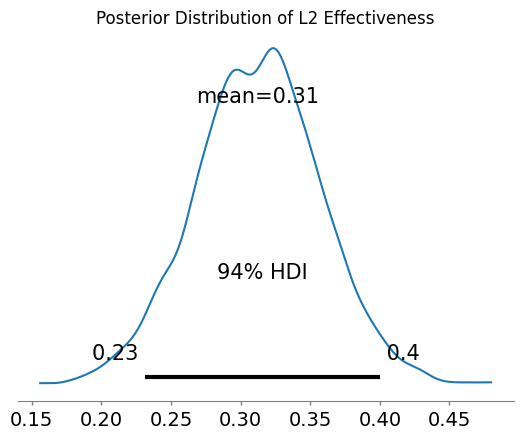

Optimal L2 norm according to posterior: 0.31240769280961106


In [3]:
import pymc as pm
import numpy as np
import matplotlib.pyplot as plt
from collections import deque

# Initialize a deque to store data for the last E iterations
E = 5  # Size of the rolling window
l2_norms_history = deque(maxlen=E)
performance_history = deque(maxlen=E)

# Simulate data entry (for demonstration purposes)
# In practice, fill these with actual L2 norms and performance metrics
for _ in range(E):
    l2_norms_history.append(np.random.uniform(0.1, 2.0))
    performance_history.append(np.random.uniform(0.2, 0.8))  # Lower is better

# Bayesian model using last E iterations
with pm.Model() as model:
    # Prior for L2 norm effectiveness (assumed normally distributed)
    l2_effectiveness = pm.Normal('l2_effectiveness', mu=1.0, sigma=1.0)
    
    # Likelihood function: Gaussian likelihood
    observed_performance = pm.Normal('observed_performance', mu=l2_effectiveness, sigma=0.1, 
                                     observed=list(performance_history))
    
    # Sample from the posterior
    trace = pm.sample(1000, tune=500)  # return_inferencedata=True by default


# Plot the results
pm.plot_posterior(trace, var_names=['l2_effectiveness'])
plt.title('Posterior Distribution of L2 Effectiveness')
plt.show()

# Determine the optimal L2 norm according to the posterior
l2_samples = trace.posterior["l2_effectiveness"].values
optimal_l2 = np.mean(l2_samples)
print(f"Optimal L2 norm according to posterior: {optimal_l2}")

# Example: Update the deque with new data for the next iteration
# This simulates the process over multiple iterations
new_l2_norm = np.random.uniform(0.1, 2.0)
new_performance = np.random.uniform(0.2, 0.8)

l2_norms_history.append(new_l2_norm)
performance_history.append(new_performance)


Auto-assigning NUTS sampler...
Initializing NUTS using jitter+adapt_diag...
Multiprocess sampling (4 chains in 4 jobs)
NUTS: [alpha, beta_mn, beta_sm, beta_mu, beta_av]


Sampling 4 chains for 500 tune and 1_000 draw iterations (2_000 + 4_000 draws total) took 3 seconds.


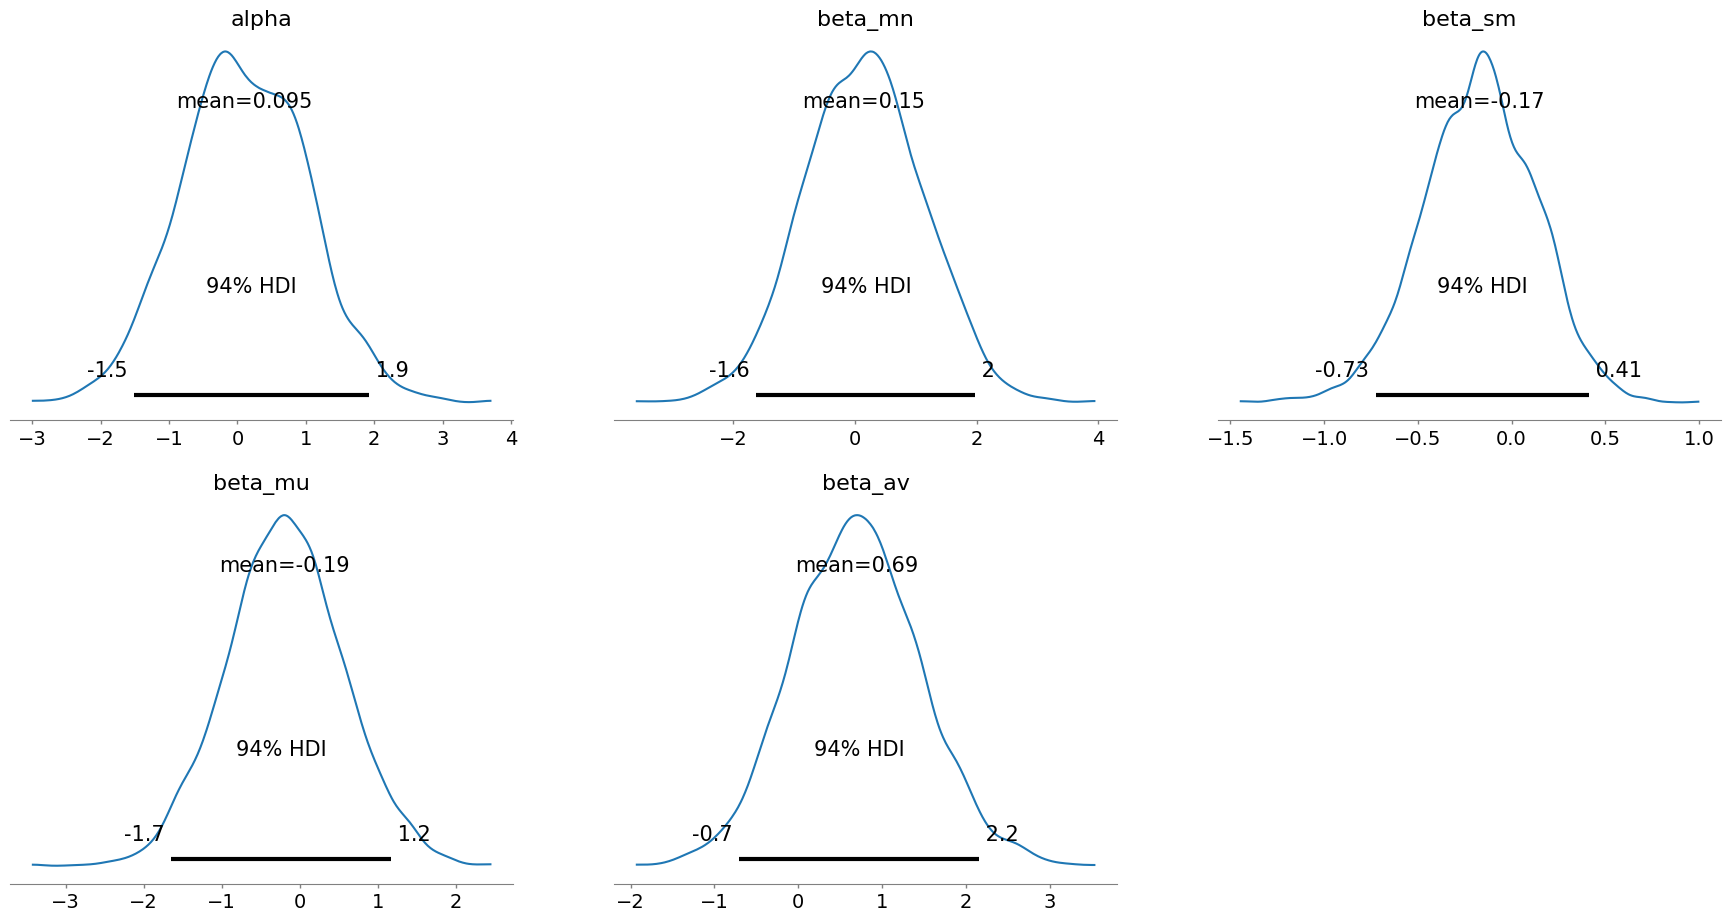

Posterior probability of inclusion over 5 iterations: [0.45102286 0.35684678 0.32541559 0.56292323 0.20650958]


In [6]:
import pymc as pm
import numpy as np
import matplotlib.pyplot as plt
import arviz as az  # Import arviz for plotting

# Simulated data for last E iterations
E = 5
m_over_n = np.random.uniform(0.1, 0.5, E)  # Ratio of malicious clients
s_m_t = np.random.randint(1, 10, E)  # Malicious clients selected
model_updates = np.random.normal(0, 1, E)  # Server model updates magnitude
attack_vectors = np.random.normal(0, 1, E)  # Attack vector magnitude

# Assume binary outcome whether malicious model was included or not
inclusion_outcomes = np.random.binomial(1, 0.5, E)  # For demonstration

# Bayesian model
with pm.Model() as model:
    # Priors for model parameters
    alpha = pm.Normal('alpha', mu=0, sigma=1)
    beta_mn = pm.Normal('beta_mn', mu=0, sigma=1)
    beta_sm = pm.Normal('beta_sm', mu=0, sigma=1)
    beta_mu = pm.Normal('beta_mu', mu=0, sigma=1)
    beta_av = pm.Normal('beta_av', mu=0, sigma=1)
    
    # Logistic model for inclusion probability
    logit_p = (alpha + beta_mn * m_over_n + beta_sm * s_m_t +
               beta_mu * model_updates + beta_av * attack_vectors)
    p_inclusion = pm.Deterministic('p_inclusion', pm.math.sigmoid(logit_p))
    
    # Likelihood
    y_obs = pm.Bernoulli('y_obs', p=p_inclusion, observed=inclusion_outcomes)
    
    # Posterior sampling
    trace = pm.sample(1000, tune=500)  # Default returns InferenceData

# Posterior analysis
az.plot_posterior(trace, var_names=['alpha', 'beta_mn', 'beta_sm', 'beta_mu', 'beta_av'])
plt.show()

# Analyze posterior probability
posterior_inclusion_prob = trace.posterior['p_inclusion'].mean(dim=('chain', 'draw')).values
print(f"Posterior probability of inclusion over {E} iterations: {posterior_inclusion_prob}")
